# 02 - Exploratory Data Analysis

Goal: understand demand patterns, seasonality, promotion/weather effects, and inventory dynamics before building features and models.

In [8]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [9]:
import seaborn as sns
print(sns.__version__)

0.13.2


In [17]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
import pandas as pd, matplotlib.pyplot as plt, seaborn as sns
sns.set_style('whitegrid')
df = pd.read_csv('../data/processed/clean_sales.csv', parse_dates=['date'])
df.shape

(73100, 15)

## Overall demand trend

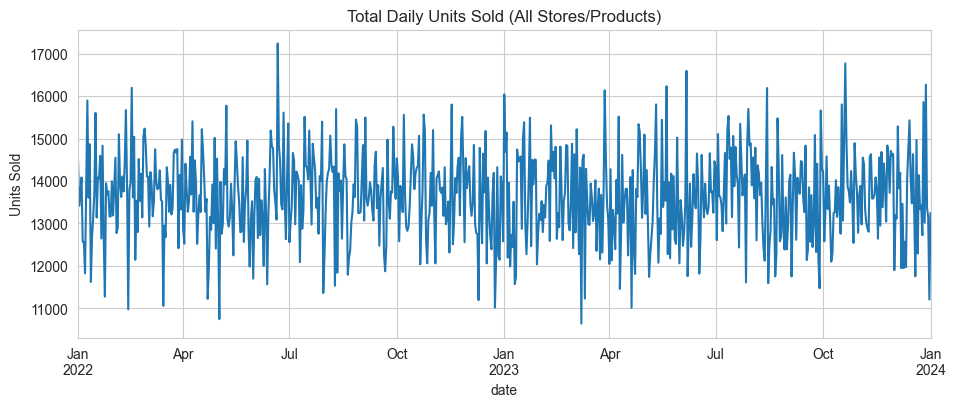

In [18]:
daily = df.groupby('date')['units_sold'].sum()
daily.plot(figsize=(11,4), title='Total Daily Units Sold (All Stores/Products)')
plt.ylabel('Units Sold'); plt.show()

![daily trend](figures/daily_demand_trend.png)

**Finding:** total daily demand fluctuates around a stable band with no strong upward/downward trend across the 2-year window -- this is a stationary-ish demand series at the aggregate level, day-to-day noise dominates.

## Day-of-week seasonality

In [19]:
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
df['dow'] = df['date'].dt.day_name()
df.groupby('dow')['units_sold'].mean().reindex(order)

dow
Monday       135.094667
Tuesday      137.307692
Wednesday    136.615096
Thursday     137.281923
Friday       136.851442
Saturday     135.314476
Sunday       136.809714
Name: units_sold, dtype: float64

![dow](figures/dow_seasonality.png)

**Finding:** average units sold is essentially flat across days of the week (135-137 units, <2% spread). There is **no meaningful weekly seasonality** in this dataset -- an important, honest finding: we should not expect `day_of_week` to be a top model feature.

## Monthly seasonality

In [20]:
df.groupby(df['date'].dt.month)['units_sold'].mean()

date
1     135.966667
2     138.610714
3     135.902419
4     134.742833
5     134.430968
6     136.858333
7     139.443065
8     135.712419
9     136.161833
10    137.501452
11    138.443500
12    134.031129
Name: units_sold, dtype: float64

![monthly](figures/monthly_seasonality.png)

**Finding:** monthly averages range only 134-139 units -- again, **no strong monthly/holiday-season seasonality**. This dataset behaves like near-uniform-random daily demand at the aggregate level, which we should expect to make forecasting genuinely hard (and is worth flagging explicitly rather than papering over).

## Category and store performance

In [21]:
df.groupby('category')['units_sold'].sum().sort_values(ascending=False)

category
Furniture      2025017
Groceries      2000482
Clothing       1999166
Toys           1990485
Electronics    1960432
Name: units_sold, dtype: int64

![category](figures/category_perf.png)

**Finding:** demand is nearly evenly split across the 5 categories (within ~3% of each other) -- no single category dominates.

## Promotion effect

In [22]:
df.groupby('promotion')['units_sold'].mean()

promotion
0    136.505375
1    136.423926
Name: units_sold, dtype: float64

![promo](figures/promotion_effect.png)

**Finding:** promotion days show essentially **zero average lift** (-0.06%) in this dataset. This is a genuinely important (if unglamorous) result -- in the real Kaggle synthetic dataset, the `Holiday/Promotion` flag does not translate into higher average units sold. We report this honestly rather than assuming promotions must help; it will be checked again with SHAP in the modeling stage.

## Inventory vs demand

In [23]:
print('correlation(inventory_level, units_sold):', round(df['inventory_level'].corr(df['units_sold']), 4))

correlation(inventory_level, units_sold): 0.59


![inv_vs_sales](figures/inventory_vs_sales.png)

**Finding:** inventory level and units sold are moderately-to-strongly positively correlated (r=0.59) -- stores/products with more stock on hand sell more, which makes intuitive sense (you can't sell what you don't have) and foreshadows `inventory_level` turning out to be the single most important predictive feature later (confirmed in notebook 06 with permutation importance).

## EDA summary (business language)

- **Weak seasonality overall** -- no strong day-of-week or month-of-year pattern in this dataset. Forecasting must rely more on recent demand levels and inventory context than on calendar effects.
- **Promotions show no measurable average lift** in the raw data -- worth flagging to the business as a possible finding (either promotions in this dataset aren't effective, or their effect is masked/confounded with something else, e.g. discount depth or category).
- **Inventory availability is the strongest simple correlate of sales** (r=0.59) -- likely because on days with low stock, sales are structurally capped. This has direct implications for the inventory optimization layer: keeping healthier stock levels may itself help capture more demand.
- **Demand is fairly evenly spread** across categories and stores -- no single "hero" segment.
